# 📈 Time Series Analysis & Forecasting
**Task:** Analyze and model time-series data to forecast future values.  
**Requirements:** Decompose series, smooth, build ARIMA/SARIMA model, evaluate using RMSE.  
**Tools:** `pandas`, `statsmodels`, `matplotlib`

✅ Data loaded successfully


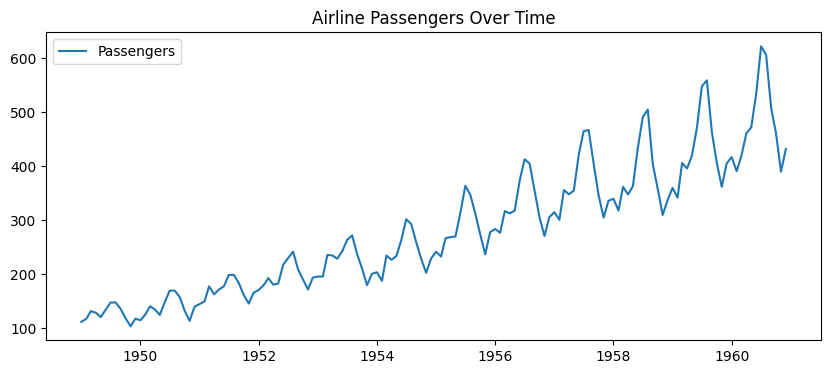

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Load Data
df = pd.read_csv('data/airline_passengers.csv', parse_dates=['Month'], index_col='Month')
print('✅ Data loaded successfully')

plt.figure(figsize=(10, 4))
plt.plot(df.index, df['Passengers'], label='Passengers')
plt.title('Airline Passengers Over Time')
plt.legend()
plt.show()

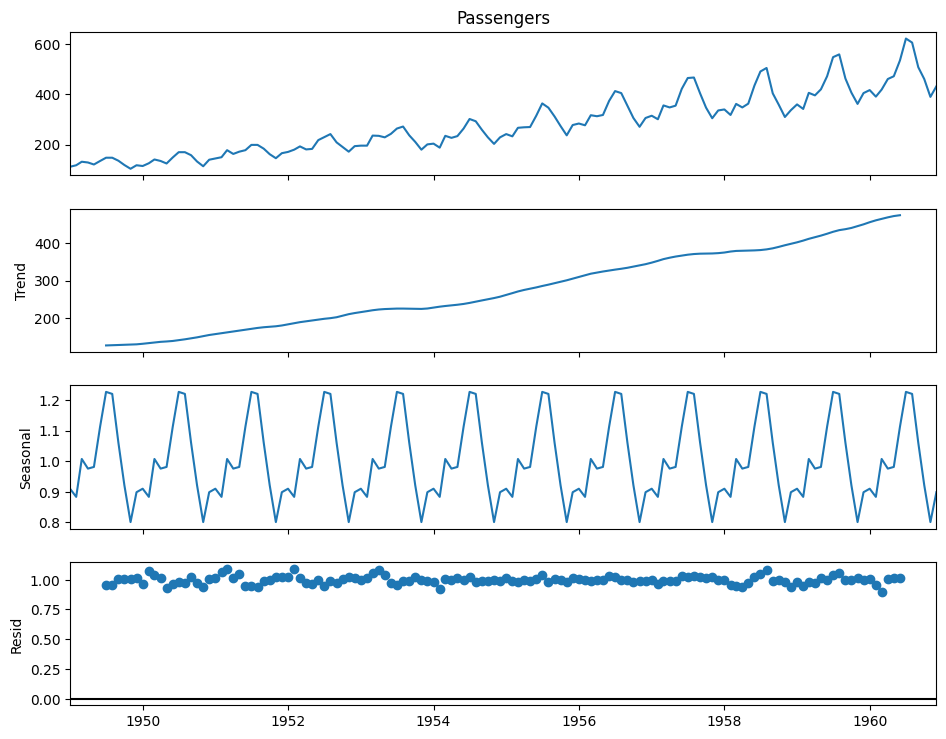

In [2]:
# Decompose Time Series
decomposition = seasonal_decompose(df['Passengers'], model='multiplicative')
fig = decomposition.plot()
fig.set_size_inches(10, 8)
plt.show()

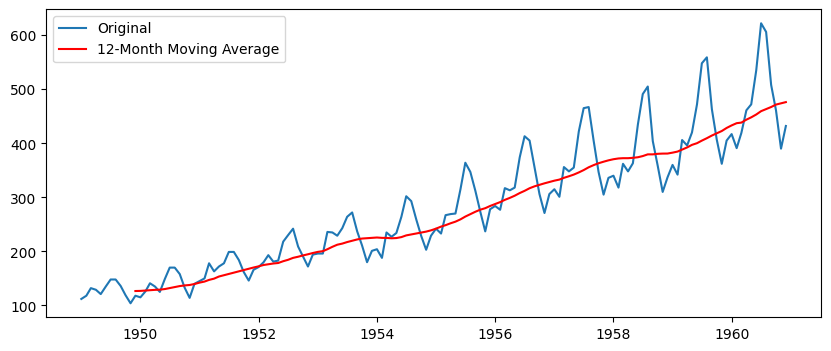

In [3]:
# Moving Average Smoothing
df['MA_12'] = df['Passengers'].rolling(window=12).mean()
plt.figure(figsize=(10, 4))
plt.plot(df.index, df['Passengers'], label='Original')
plt.plot(df.index, df['MA_12'], color='red', label='12-Month Moving Average')
plt.legend()
plt.show()

✅ ARIMA Model RMSE: 80.66


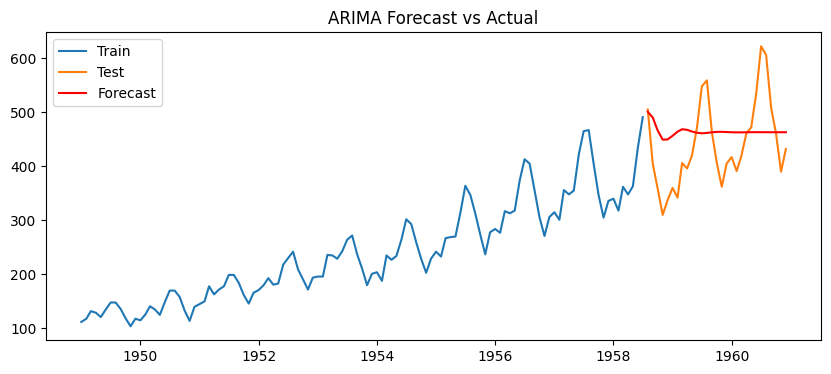

In [4]:
# ARIMA Forecasting
# Train/Test Split (80/20)
train_size = int(len(df) * 0.8)
train, test = df['Passengers'].iloc[:train_size], df['Passengers'].iloc[train_size:]

# Fit ARIMA (Example order, usually found via auto_arima or ACF/PACF)
model = ARIMA(train, order=(5, 1, 0))
model_fit = model.fit()

# Predict
predictions = model_fit.forecast(steps=len(test))

# Evaluate
rmse = np.sqrt(mean_squared_error(test, predictions))
print(f'✅ ARIMA Model RMSE: {rmse:.2f}')

plt.figure(figsize=(10, 4))
plt.plot(train.index, train, label='Train')
plt.plot(test.index, test, label='Test')
plt.plot(test.index, predictions, color='red', label='Forecast')
plt.title('ARIMA Forecast vs Actual')
plt.legend()
plt.show()

In [5]:

import joblib
import os
import pandas as pd

os.makedirs('outputs', exist_ok=True)
os.makedirs('models', exist_ok=True)

# Save ARIMA model
joblib.dump(model_fit, 'models/arima_model.pkl')

# Save predictions
output_df = pd.DataFrame({'Actual': test, 'Forecast': predictions})
output_df.to_csv('outputs/arima_forecast.csv')
print('✅ Saved models and outputs successfully!')


✅ Saved models and outputs successfully!
